In [1]:
import pandas as pd
import numpy as np
import joblib

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("datasets/UNSW_NB15_testing_set.csv")

In [3]:
X = df.drop(columns=["label", "attack_cat"])
y = df["label"]

In [7]:
model = joblib.load(r"../Python/models/isolation_forest.pkl")

In [16]:
import joblib
import json
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Load expected feature list from training metadata
with open(r"../../src/models/feature_meta.json") as f:
    meta = json.load(f)
expected_features = meta["feature_cols"]

# Keep only the 38 features the scaler was trained on
X = X[expected_features]

# Encode ALL object/string columns
for col in X.columns:
    if X[col].dtype == object:
        le = LabelEncoder()
        X[col] = le.fit_transform(X[col].astype(str))

# Load scaler and transform
scaler = joblib.load(r"../Python/models/scaler.pkl")
X_scaled = scaler.transform(X)

c:\Users\roden\OneDrive - University of Stirling\Documents\Final_Year_Project\NIDS\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [17]:
y_pred = model.predict(X)

# Convert -1 to 1 (attack), 1 to 0 (normal)
y_pred = [1 if x == -1 else 0 for x in y_pred]

c:\Users\roden\OneDrive - University of Stirling\Documents\Final_Year_Project\NIDS\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but IsolationForest was fitted without feature names
  warnings.warn(


In [18]:
print(classification_report(y, y_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00     37000
           1       0.55      1.00      0.71     45332

    accuracy                           0.55     82332
   macro avg       0.28      0.50      0.36     82332
weighted avg       0.30      0.55      0.39     82332



c:\Users\roden\OneDrive - University of Stirling\Documents\Final_Year_Project\NIDS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\roden\OneDrive - University of Stirling\Documents\Final_Year_Project\NIDS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\roden\OneDrive - University of Stirling\Documents\Final_Year_Project\NIDS\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in lab

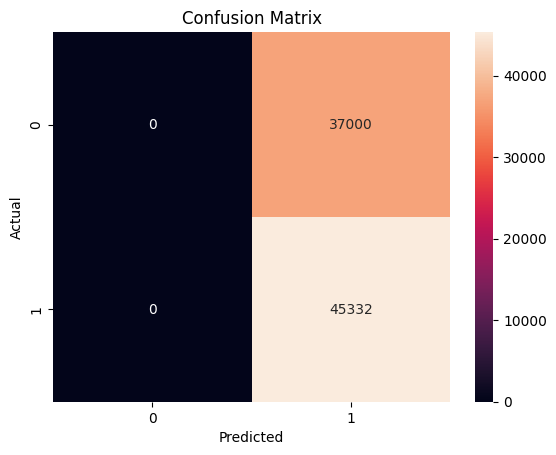

In [20]:
cm = confusion_matrix(y, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig("confusion_matrix.png")
plt.show()

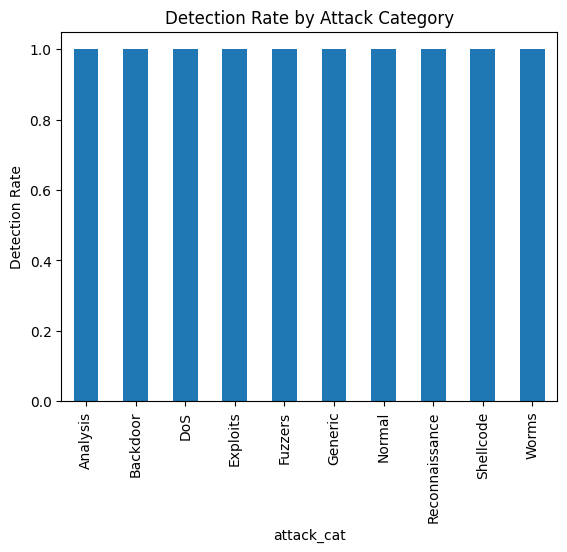

In [21]:
df["pred"] = y_pred

attack_perf = df.groupby("attack_cat")["pred"].mean()

attack_perf.plot(kind="bar")
plt.title("Detection Rate by Attack Category")
plt.ylabel("Detection Rate")

plt.savefig("attack_detection.png")
plt.show()

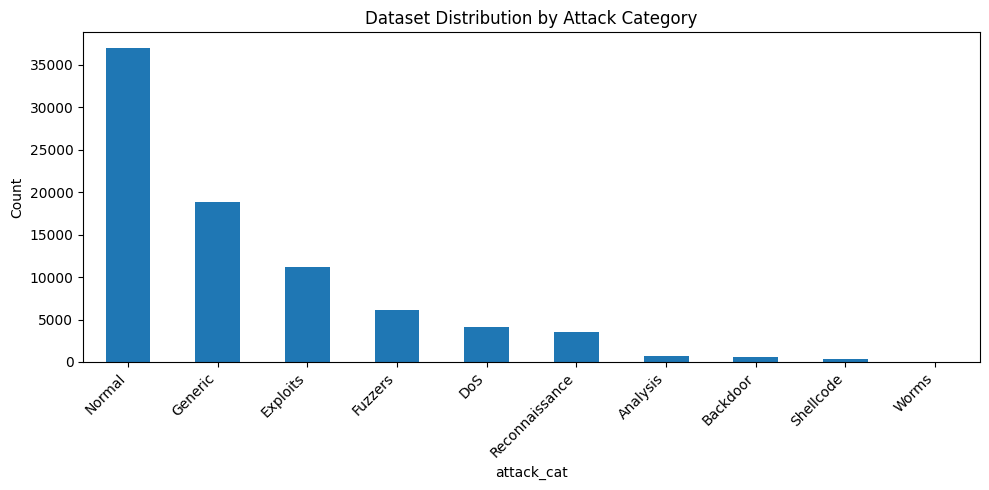

In [22]:
df["attack_cat"].value_counts().plot(kind="bar", figsize=(10,5))
plt.title("Dataset Distribution by Attack Category")
plt.ylabel("Count")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("dataset_distribution.png")
plt.show()

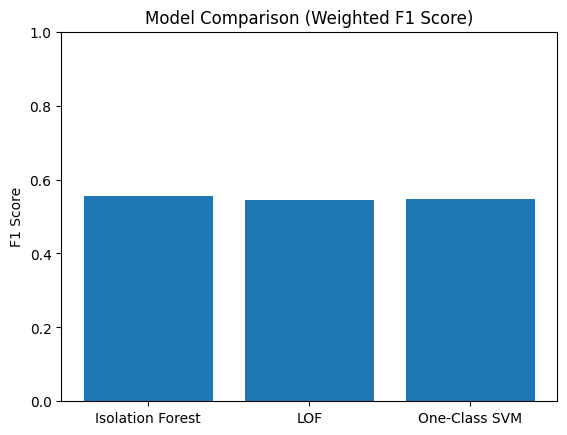

In [23]:
from sklearn.metrics import f1_score

if_model = joblib.load(r"../Python/models/isolation_forest.pkl")
lof_model = joblib.load(r"../Python/models/local_outlier_factor.pkl")
svm_model = joblib.load(r"../Python/models/one_class_svm.pkl")

results = {}
for name, model in [("Isolation Forest", if_model), ("LOF", lof_model), ("One-Class SVM", svm_model)]:
    preds = model.predict(X_scaled)
    preds = [1 if x == -1 else 0 for x in preds]
    results[name] = f1_score(y, preds, average='weighted')

plt.bar(results.keys(), results.values())
plt.title("Model Comparison (Weighted F1 Score)")
plt.ylabel("F1 Score")
plt.ylim(0, 1)
plt.savefig("model_comparison.png")
plt.show()